# EDA CIFAR-10 — Lab 2
Notebook kiểm tra dữ liệu, phân bố lớp và tiền xử lý của pipeline Lab 2. Chạy **Restart Kernel → Run All** với kernel **Python (Lab 2)**. Dữ liệu CIFAR-10 được tải vào `data/` nếu chưa có. Mọi hình được lưu trong `outputs/eda/`.

Seed lấy từ `src/config.py`. Thống kê trên ảnh gốc và các phép kiểm tra không cập nhật trọng số model.

In [1]:
from pathlib import Path
import sys
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from torchvision import transforms

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "src" / "dataset.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục lab2 hoặc notebooks của lab2.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.config import DEFAULT_SEED, DATA_DIR, CIFAR10_CLASSES, IMAGENET_MEAN, IMAGENET_STD
from src.dataset import get_cifar10_dataloaders

SEED = DEFAULT_SEED
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
EDA_DIR = PROJECT_ROOT / "outputs" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
saved_figures = []

def save_show(fig, name):
    path = EDA_DIR / name
    fig.savefig(path, dpi=180, bbox_inches="tight")
    saved_figures.append(path)
    plt.show()
    plt.close(fig)

print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)
print("Seed:", SEED, "| PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

Project: D:\CODE\HKND\CODE\reference_project\lab2
Python: d:\CODE\HKND\CODE\reference_project\lab2\.venv\Scripts\python.exe
Seed: 42 | PyTorch: 2.15.0+cpu | CUDA: False


**Nhận xét.** Seed và thư mục dữ liệu được lấy từ cấu hình dự án. Chạy từ `lab2/` hoặc `lab2/notebooks/` đều dùng chung nguồn dữ liệu và thư mục đầu ra.

## 1. Nạp dữ liệu và kiểm tra cách chia tập

In [2]:
train_loader, val_loader, test_loader = get_cifar10_dataloaders(
    data_dir=str(DATA_DIR), batch_size=32, num_workers=0,
    pin_memory=False, subset_ratio=1.0, dry_run=False, seed=SEED,
)
splits = {"Train": train_loader.dataset, "Validation": val_loader.dataset, "Test": test_loader.dataset}
sizes = {name: len(subset) for name, subset in splits.items()}
assert sizes == {"Train": 40000, "Validation": 10000, "Test": 10000}, sizes
train_ids = list(splits["Train"].indices)
val_ids = list(splits["Validation"].indices)
test_ids = list(splits["Test"].indices)
expected = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED)).tolist()
assert train_ids == expected[:40000]
assert val_ids == expected[40000:]
assert set(train_ids).isdisjoint(val_ids)
assert len(set(train_ids) | set(val_ids)) == 50000
assert test_ids == list(range(10000))
assert splits["Train"].dataset is not splits["Validation"].dataset
display(pd.DataFrame({"split": list(sizes), "samples": list(sizes.values())}))
print("PASS — đúng split của pipeline, đủ số mẫu và Train/Validation không trùng chỉ số.")

,split,samples
0,Train,40000
1,Validation,10000
2,Test,10000


PASS — đúng split của pipeline, đủ số mẫu và Train/Validation không trùng chỉ số.


**Nhận xét.** Các assertion xác nhận tỷ lệ 40.000/10.000/10.000 và tái lập chính xác hoán vị từ seed của pipeline. Train và Validation cùng lấy từ 50.000 ảnh huấn luyện gốc, còn Test lấy từ bộ Test chính thức. Chỉ số Test và Train thuộc hai không gian dữ liệu khác nhau, vì vậy không dùng giao của hai tập số nguyên để kết luận trùng ảnh.

## 2. Phân bố 10 lớp

,Train,Validation,Test
airplane,4027,973,1000
automobile,3990,1010,1000
bird,3994,1006,1000
cat,4033,967,1000
deer,4037,963,1000
dog,3976,1024,1000
frog,3975,1025,1000
horse,3965,1035,1000
ship,4002,998,1000
truck,4001,999,1000


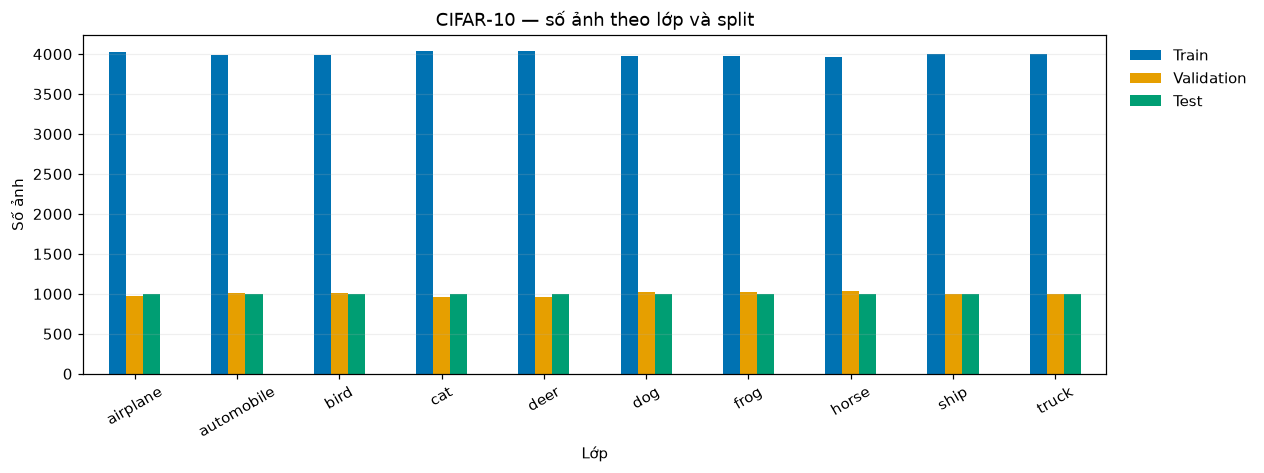

,Train,Validation,Test
Tỷ lệ % theo lớp,,,
airplane,10.07,9.73,10.0
automobile,9.98,10.10,10.0
bird,9.98,10.06,10.0
cat,10.08,9.67,10.0
deer,10.09,9.63,10.0
dog,9.94,10.24,10.0
frog,9.94,10.25,10.0
horse,9.91,10.35,10.0
ship,10.01,9.98,10.0


In [3]:
counts = pd.DataFrame({
    name: np.bincount(np.asarray(subset.dataset.targets)[subset.indices], minlength=10)
    for name, subset in splits.items()
}, index=CIFAR10_CLASSES)
assert counts.sum().to_dict() == sizes
display(counts)
fig, ax = plt.subplots(figsize=(12, 4))
counts.plot.bar(ax=ax, rot=30, color=['#0072B2', '#E69F00', '#009E73'])
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
ax.set(title="CIFAR-10 — số ảnh theo lớp và split", ylabel="Số ảnh", xlabel="Lớp")
ax.grid(axis="y", alpha=.2)
save_show(fig, "class_distribution.png")
display((counts / counts.sum() * 100).round(2).rename_axis("Tỷ lệ % theo lớp"))

**Nhận xét.** Tách tập bằng hoán vị ngẫu nhiên có seed nên số ảnh từng lớp trong Train/Validation có thể khác nhau. Bảng tỷ lệ cho phép kiểm tra mức chênh lệch trước khi diễn giải metric từng lớp. Bộ chia hiện tại không thực hiện stratification.

## 3. Ảnh gốc mẫu theo từng lớp

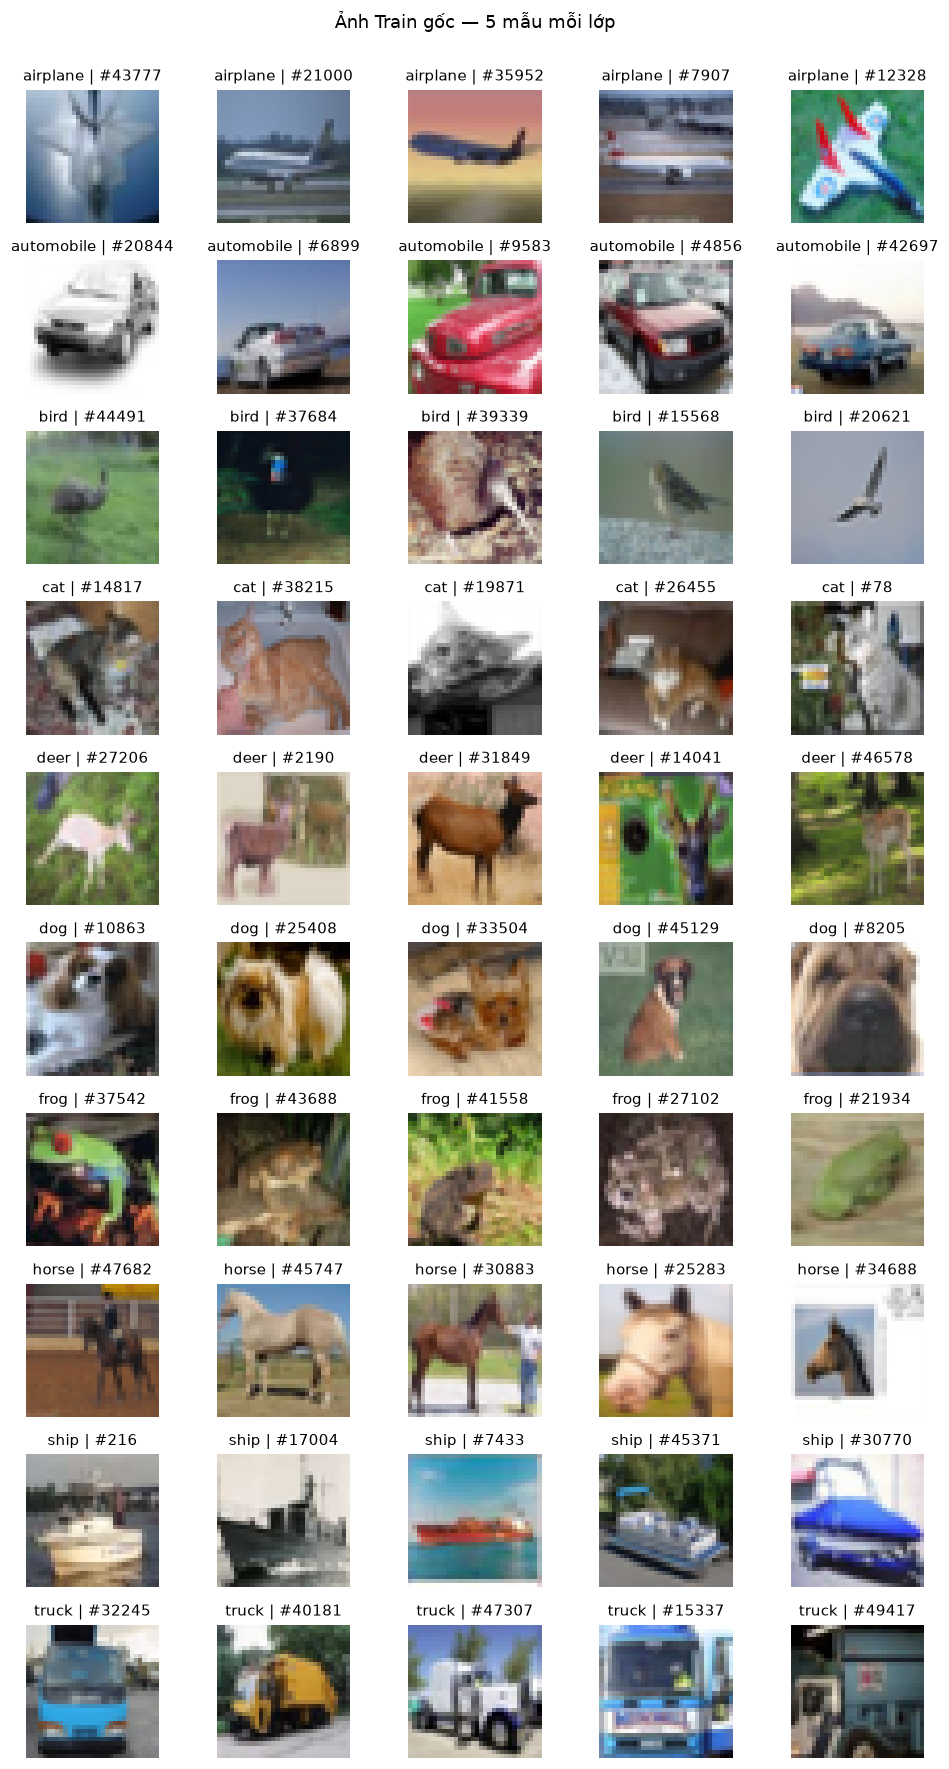

In [4]:
raw_train = splits["Train"].dataset
labels_train = np.asarray(raw_train.targets)
fig, axes = plt.subplots(10, 5, figsize=(9, 16))
for class_id, class_name in enumerate(CIFAR10_CLASSES):
    ids = np.asarray(train_ids)[labels_train[train_ids] == class_id][:5]
    for col, sample_id in enumerate(ids):
        ax = axes[class_id, col]
        ax.imshow(raw_train.data[sample_id], interpolation="nearest")
        assert labels_train[sample_id] == class_id
        ax.set_title(f"{class_name} | #{sample_id}", fontsize=10)
        ax.axis("off")
fig.suptitle("Ảnh Train gốc — 5 mẫu mỗi lớp", y=1.002)
fig.tight_layout()
save_show(fig, "class_samples.png")

**Nhận xét.** Gallery lấy mẫu từ Train, ghi rõ nhãn và ID ảnh gốc để đối chiếu. Ảnh 32×32 có ít chi tiết và có thể chứa nền hoặc đối tượng nhỏ, đây là yếu tố cần xem xét khi phân tích nhầm lớp ở notebook đánh giá.

## 4. Shape, dtype, miền pixel và thống kê RGB

,split,shape,dtype,pixel_min,pixel_max
0,Train,"(40000, 32, 32, 3)",uint8,0,255
1,Validation,"(10000, 32, 32, 3)",uint8,0,255
2,Test,"(10000, 32, 32, 3)",uint8,0,255


,split,channel,mean_0_1,std_0_1
0,Train,R,0.49172,0.24705
1,Train,G,0.48256,0.24351
2,Train,B,0.44712,0.26167
3,Validation,R,0.49013,0.24694
4,Validation,G,0.48055,0.24340
5,Validation,B,0.44418,0.26126
6,Test,R,0.49421,0.24665
7,Test,G,0.48513,0.24289
8,Test,B,0.45041,0.26159


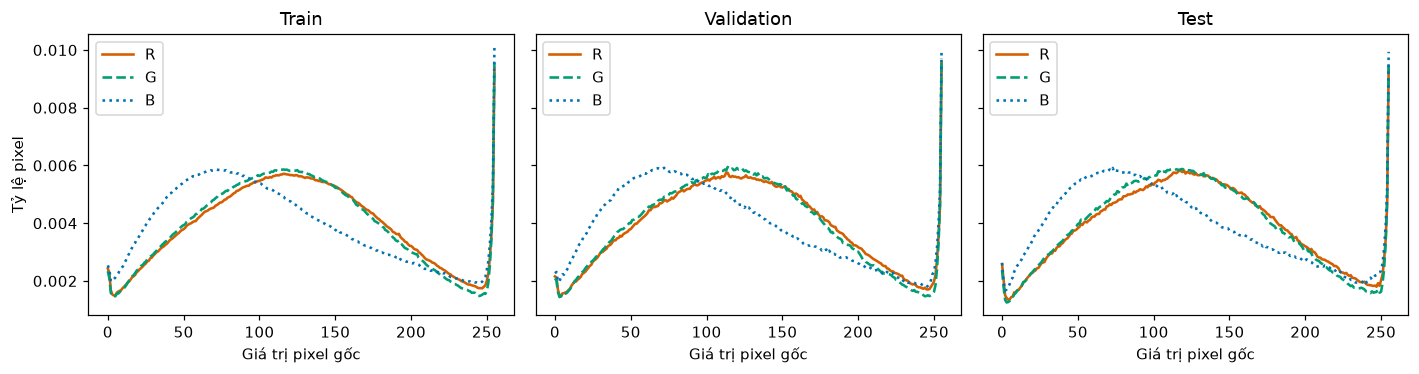

In [5]:
summary_rows = []
rgb_rows = []
histograms = {}
for name, subset in splits.items():
    raw = subset.dataset.data
    assert raw.dtype == np.uint8 and raw.shape[1:] == (32, 32, 3)
    sums = np.zeros(3, dtype=np.float64)
    square_sums = np.zeros(3, dtype=np.float64)
    hist = np.zeros((256, 3), dtype=np.int64)
    pixel_count = 0
    minimum, maximum = 255, 0
    for start in range(0, len(subset), 1000):
        batch = raw[np.asarray(subset.indices[start:start + 1000])]
        minimum = min(minimum, int(batch.min()))
        maximum = max(maximum, int(batch.max()))
        pixels = batch.reshape(-1, 3)
        scaled = pixels.astype(np.float64) / 255.0
        sums += scaled.sum(axis=0)
        square_sums += np.square(scaled).sum(axis=0)
        pixel_count += len(pixels)
        for channel in range(3):
            hist[:, channel] += np.bincount(pixels[:, channel], minlength=256)
    mean = sums / pixel_count
    std = np.sqrt(np.maximum(square_sums / pixel_count - mean ** 2, 0))
    summary_rows.append({"split": name, "shape": (len(subset), 32, 32, 3),
                         "dtype": str(raw.dtype), "pixel_min": minimum, "pixel_max": maximum})
    for c, channel in enumerate("RGB"):
        rgb_rows.append({"split": name, "channel": channel,
                         "mean_0_1": mean[c], "std_0_1": std[c]})
    histograms[name] = hist
display(pd.DataFrame(summary_rows))
rgb_stats = pd.DataFrame(rgb_rows)
display(rgb_stats.round(5))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, hist) in zip(axes, histograms.items()):
    for c, (color, style) in enumerate(zip(['#D55E00', '#009E73', '#0072B2'], ['-', '--', ':'])):
        ax.plot(np.arange(256), hist[:, c] / hist[:, c].sum(), color=color, linestyle=style, label="RGB"[c], linewidth=1.7)
    ax.set(title=name, xlabel="Giá trị pixel gốc")
    ax.legend()
axes[0].set_ylabel("Tỷ lệ pixel")
fig.tight_layout()
save_show(fig, "rgb_histograms.png")

**Nhận xét.** Thống kê RGB được tính trên toàn bộ ảnh gốc của mỗi split theo từng lô nhỏ. Mean/std trong bảng dùng thang 0–1, histogram dùng pixel 0–255. Pipeline sử dụng mean/std ImageNet vì dùng model pretrained, nên các thống kê mô tả CIFAR-10 ở đây không tự thay thế thông số chuẩn hóa của pipeline.

## 5. So sánh trước và sau transform

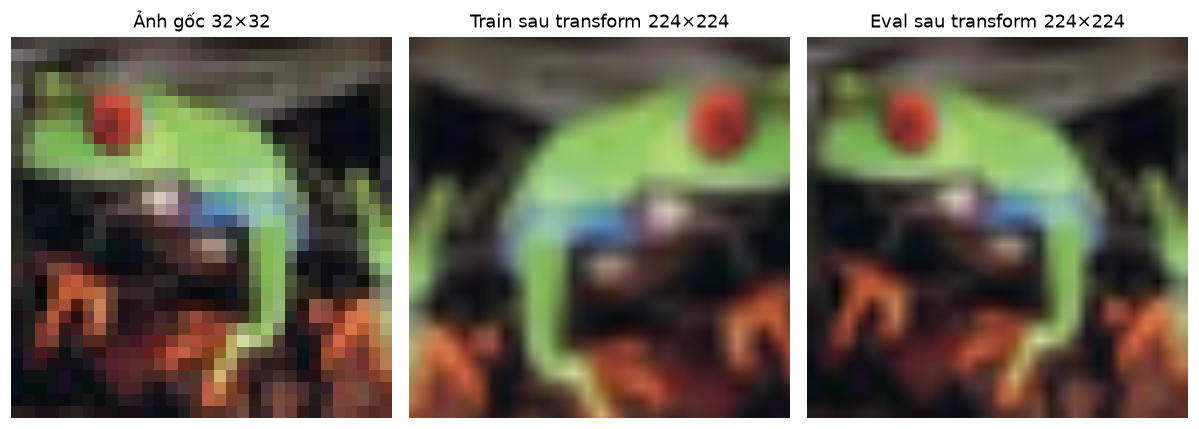

,transform,shape,dtype,normalized_min,normalized_max
0,Train,"(3, 224, 224)",torch.float32,-2.066530,1.815826
1,Eval,"(3, 224, 224)",torch.float32,-2.117904,1.815826


In [6]:
train_tf = splits["Train"].dataset.transform
val_tf = splits["Validation"].dataset.transform
test_tf = splits["Test"].dataset.transform
sample_id = train_ids[0]
raw_image = Image.fromarray(raw_train.data[sample_id])
torch.manual_seed(SEED)
train_tensor = train_tf(raw_image)
eval_tensor = val_tf(raw_image)
mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def display_tensor(tensor):
    return (tensor * std_tensor + mean_tensor).clamp(0, 1).permute(1, 2, 0).numpy()

assert train_tensor.shape == eval_tensor.shape == (3, 224, 224)
assert train_tensor.dtype == eval_tensor.dtype == torch.float32
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(raw_image, interpolation="nearest")
axes[1].imshow(display_tensor(train_tensor))
axes[2].imshow(display_tensor(eval_tensor))
for ax, title in zip(axes, ["Ảnh gốc 32×32", "Train sau transform 224×224", "Eval sau transform 224×224"]):
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
save_show(fig, "transform_comparison.png")
display(pd.DataFrame([
    {"transform": name, "shape": tuple(tensor.shape), "dtype": str(tensor.dtype),
     "normalized_min": tensor.min().item(), "normalized_max": tensor.max().item()}
    for name, tensor in [("Train", train_tensor), ("Eval", eval_tensor)]
]))

**Nhận xét.** Hai ảnh sau transform đã được hoàn nguyên chuẩn hóa để hiển thị. Tensor thật có thể có giá trị âm hoặc lớn hơn 1 sau Normalize, như bảng cho thấy. Resize làm tăng kích thước đầu vào và không bổ sung chi tiết mới cho ảnh gốc. Train có crop/flip ngẫu nhiên, còn Eval chỉ resize và chuẩn hóa.

## 6. Kiểm tra Validation/Test không có augmentation ngẫu nhiên

In [7]:
allowed_eval_types = [transforms.Resize, transforms.ToTensor, transforms.Normalize]
for name, subset in [("Validation", splits["Validation"]), ("Test", splits["Test"])]:
    transform = subset.dataset.transform
    actual_types = [type(step) for step in transform.transforms]
    assert actual_types == allowed_eval_types, (name, actual_types)
    for local_index in [0, 1, 10, 100, len(subset) - 1]:
        image = Image.fromarray(subset.dataset.data[subset.indices[local_index]])
        first = transform(image)
        for _ in range(3):
            assert torch.equal(first, transform(image)), (name, local_index)
    print(name, "PASS — Resize → ToTensor → Normalize; lặp lại cho tensor giống hệt.")
assert any(isinstance(step, transforms.RandomCrop) for step in train_tf.transforms)
assert any(isinstance(step, transforms.RandomHorizontalFlip) for step in train_tf.transforms)
print("Train có RandomCrop và RandomHorizontalFlip như pipeline.")
for path in saved_figures:
    assert path.is_file() and path.stat().st_size > 0
print("Đã lưu", len(saved_figures), "hình:")
for path in saved_figures:
    print(path.relative_to(PROJECT_ROOT))

Validation PASS — Resize → ToTensor → Normalize; lặp lại cho tensor giống hệt.
Test PASS — Resize → ToTensor → Normalize; lặp lại cho tensor giống hệt.
Train có RandomCrop và RandomHorizontalFlip như pipeline.
Đã lưu 4 hình:
outputs\eda\class_distribution.png
outputs\eda\class_samples.png
outputs\eda\rgb_histograms.png
outputs\eda\transform_comparison.png


**Nhận xét.** Kiểm tra danh sách kiểu transform xác nhận cả Validation và Test chỉ có Resize, ToTensor và Normalize. Việc áp dụng lặp lại trên nhiều ảnh cho tensor bằng nhau củng cố kiểm tra tính xác định. Đây là bằng chứng về preprocessing và chỉ số chia tập, chưa kiểm tra các ảnh trùng nội dung trong bộ dữ liệu gốc.